In [ ]:
import os
root = "/kaggle/input/competitions/imagenet-object-localization-challenge"
print(os.listdir(root))
print(os.listdir(f"{root}/ILSVRC/Data/CLS-LOC")[:5])
print(len(os.listdir(f"{root}/ILSVRC/Data/CLS-LOC/val")), "val images")
print(open(f"{root}/LOC_val_solution.csv").read()[:300])

In [ ]:
import os, time, numpy as np, pandas as pd, torch, torchvision.models as tvm
from PIL import Image
from torch.utils.data import Dataset, DataLoader

root = "/kaggle/input/competitions/imagenet-object-localization-challenge"
VAL = f"{root}/ILSVRC/Data/CLS-LOC/val"
wnids = [l.split()[0] for l in open(f"{root}/LOC_synset_mapping.txt")]
w2i = {w: i for i, w in enumerate(wnids)}          # same order as torchvision class indices
sol = pd.read_csv(f"{root}/LOC_val_solution.csv")
sol["label"] = sol.PredictionString.str.split().str[0].map(w2i)
sol = sol.sort_values("ImageId").reset_index(drop=True)
assert len(sol) == 50000 and sol.label.notna().all()

DEV = torch.device("cuda:0")
OUT = "/kaggle/working/accuracy_imagenet_val.csv"
MODELS = {
    "mobilenet_v3_small": tvm.MobileNet_V3_Small_Weights.DEFAULT,
    "efficientnet_b0": tvm.EfficientNet_B0_Weights.DEFAULT,
    "resnet18": tvm.ResNet18_Weights.DEFAULT,
    "resnet50": tvm.ResNet50_Weights.DEFAULT,
    "convnext_tiny": tvm.ConvNeXt_Tiny_Weights.DEFAULT,
    "vit_b_16": tvm.ViT_B_16_Weights.DEFAULT,
}

class DS(Dataset):
    def __init__(self, tf): self.tf = tf
    def __len__(self): return len(sol)
    def __getitem__(self, i):
        img = Image.open(f"{VAL}/{sol.ImageId[i]}.JPEG").convert("RGB")
        return self.tf(img), int(sol.label[i])

first = not os.path.exists(OUT)
done = set() if first else set(pd.read_csv(OUT).model.unique())
for name, w in MODELS.items():
    if name in done:
        print("skip", name); continue
    t0 = time.time()
    m32 = getattr(tvm, name)(weights=w).eval().to(DEV)
    m16 = getattr(tvm, name)(weights=w).eval().to(DEV).half()
    dl = DataLoader(DS(w.transforms()), batch_size=128, num_workers=4, shuffle=False)
    rows = []
    with torch.no_grad():
        for x, y in dl:
            x = x.to(DEV)
            p32 = m32(x).softmax(1); p16 = m16(x.half()).float().softmax(1)
            c32, t32 = p32.max(1); c16, t16 = p16.max(1)
            rows.append(pd.DataFrame({
                "model": name, "label": y.numpy(),
                "pred_fp32": t32.cpu().numpy(), "pred_fp16": t16.cpu().numpy(),
                "conf_fp32": c32.cpu().numpy(), "conf_fp16": c16.cpu().numpy()}))
    df = pd.concat(rows, ignore_index=True)
    df.insert(0, "image_id", sol.ImageId.values)
    df.to_csv(OUT, mode="a", header=not os.path.exists(OUT), index=False)
    print(name, "acc32 %.4f acc16 %.4f flips %d  %.0fs" % (
        (df.pred_fp32 == df.label).mean(), (df.pred_fp16 == df.label).mean(),
        (df.pred_fp32 != df.pred_fp16).sum(), time.time() - t0))
    del m32, m16; torch.cuda.empty_cache()
print("DONE")

In [4]:
import os
print(os.listdir("/kaggle/input"))
for sub in ["datasets"]:
    p = os.path.join("/kaggle/input", sub)
    if os.path.isdir(p):
        print(sub, "->", os.listdir(p))
        for u in os.listdir(p):
            print("  ", u, "->", os.listdir(os.path.join(p, u)))

['datasets', 'competitions']
datasets -> ['sumiyaahasan']
   sumiyaahasan -> ['accuracy-imagenet-val']


['accuracy_imagenet_val.csv']
rows: 300000
                     fp32   fp16
model                           
convnext_tiny       82.51  82.51
efficientnet_b0     77.70  77.72
mobilenet_v3_small  67.67  67.65
resnet18            69.76  69.75
resnet50            80.85  80.84
vit_b_16            81.07  81.07


/tmp/ipykernel_50/3990843527.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  acc = d.groupby("model").apply(lambda g: pd.Series({


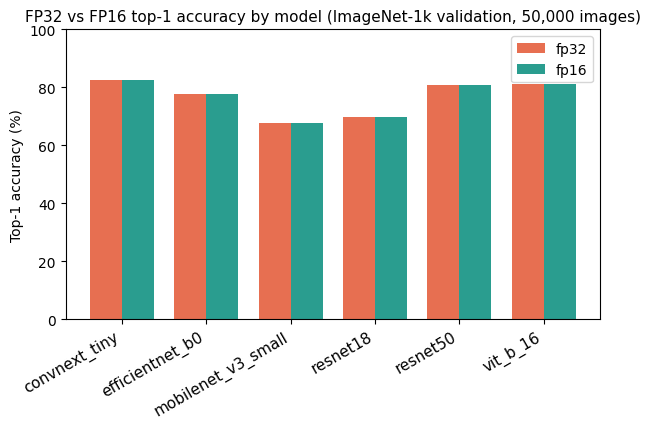

In [8]:
import glob, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt

# find the CSV that the accuracy notebook saved
import os
p = "/kaggle/input/datasets/sumiyaahasan/accuracy-imagenet-val/accuracy_imagenet_val.csv"
print(os.listdir("/kaggle/input/datasets/sumiyaahasan/accuracy-imagenet-val"))
d = pd.read_csv(p)
print("rows:", len(d))

acc = d.groupby("model").apply(lambda g: pd.Series({
    "fp32": 100 * (g.pred_fp32 == g.label).mean(),
    "fp16": 100 * (g.pred_fp16 == g.label).mean()})).sort_index()
print(acc.round(2))

x = np.arange(len(acc)); w = 0.38
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.bar(x - w/2, acc.fp32, w, label="fp32", color="#e76f51")
ax.bar(x + w/2, acc.fp16, w, label="fp16", color="#2a9d8f")
ax.set_xticks(x); ax.set_xticklabels(acc.index, rotation=30, ha="right", fontsize=11)
ax.set_ylim(0, 100); ax.set_ylabel("Top-1 accuracy (%)")
ax.set_title("FP32 vs FP16 top-1 accuracy by model (ImageNet-1k validation, 50,000 images)", fontsize=11)
ax.legend(loc="upper right", fontsize=10)
fig.tight_layout()
fig.savefig("/kaggle/working/Figure4d_imagenet_accuracy.png", dpi=250)
fig.savefig("/kaggle/working/Figure4d_imagenet_accuracy.pdf")
plt.show()